In [ ]:
# import streamlit as st
import pandas as pd
import numpy as np
from datetime import datetime, timedelta, timezone
from catboost import CatBoostRegressor
import json
import requests
from io import StringIO
import holidays
from zoneinfo import ZoneInfo




SHORTNAME_FILE = "true_valid_stations_list.json"


CITIBIKE_STATUS_URL = "https://gbfs.citibikenyc.com/gbfs/en/station_status.json"
CITIBIKE_INFO_URL = "https://gbfs.citibikenyc.com/gbfs/en/station_information.json"

with open('true_valid_stations_list.json', 'r') as f:
    shortnames = json.load(f)

shortnames = set(shortnames)

def pull_data():
    status_resp = requests.get(CITIBIKE_STATUS_URL)
    info_resp = requests.get(CITIBIKE_INFO_URL)

    status_data = status_resp.json()["data"]["stations"]
    info_data = info_resp.json()["data"]["stations"]


    df_status = pd.DataFrame(status_data)
    df_info = pd.DataFrame(info_data)


    df = df_status.merge(df_info, on="station_id")

    df = df[df["short_name"].isin(shortnames)].copy()

    # Select useful columns
    df = df[[
        "station_id",
        "short_name",
        "name",
        "num_bikes_available",
        "num_docks_available",
        "lat",
        "lon",
        "last_reported"
    ]]

    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])
    df['shortname'] = df['short_name']
    df = df.drop('short_name', axis = 1)
    

    return df

def add_features(df):
    df["timestamp"] = pd.to_datetime(
        df["last_reported"], unit="s", origin="unix", utc=True
    ).dt.tz_convert("America/New_York")
    
    df = df.drop('last_reported', axis=1)
    df['shortname'] = df['short_name']
    df = df.drop('short_name', axis = 1)

    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['minute'] = df['timestamp'].dt.minute
    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])
    df['IsRushHour'] = ((df['Hour'].isin([7,8,9,16,17,18])) & (df['IsWeekend'] == 0)).astype(int)

    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)

    return df

def add_Xfeatures(df):
    df['timestamp'] = pd.to_datetime(df['timestamp'], unit='s', utc = True)
    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['minute'] = df['timestamp'].dt.minute
    df['IsRushHour'] = ((df['Hour'].isin([7,8,9,16,17,18])) & (df['IsWeekend'] == 0)).astype(int)
    df['lat'] = df['shortname'].map(shortname_to_lat)
    df['lon'] = df['shortname'].map(shortname_to_lon)

    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)
    

    return df





In [ ]:
stations_df = pd.read_csv('citibike-stations.csv')
shortname_to_lat = dict(zip(stations_df['short_name'], stations_df['lat']))
shortname_to_lon = dict(zip(stations_df['short_name'], stations_df['lon']))
shortname_to_name = dict(zip(stations_df['short_name'], stations_df['name']))

KeyError: '5569.07'

In [3]:
model = CatBoostRegressor()
model.load_model('Working_model.cbm')

curr = datetime.now(ZoneInfo("US/Eastern"))
end = curr + timedelta(days = 7)


timestamps = []

# construct column of predictions times for dataframe for predictions
while (curr < end):
    timestamps.append(curr)
    curr += timedelta(hours = 1)

timestamp_df = pd.DataFrame({'timestamp': timestamps})

predictions = {}

# prepare the data for prediction for each station
for shortname in shortnames:
    pred_df = timestamp_df.copy()
    pred_df['shortname'] = shortname
    pred_df = add_Xfeatures(pred_df)
    predictions[shortname] = pred_df

# make predictions
for name, data in predictions.items():
    x = data.drop('timestamp', axis = 1)
    data['predictions'] = model.predict(x)





In [6]:
datetime.now(ZoneInfo("US/Eastern"))

datetime.datetime(2026, 2, 18, 14, 7, 52, 615581, tzinfo=zoneinfo.ZoneInfo(key='US/Eastern'))

In [5]:
predictions['5159.04']

,timestamp,shortname,Month,Day,Hour,IsWeekend,minute,IsRushHour,lat,lon,IsHoliday,IsNonWorkingDay,predictions
0,2026-02-18 19:06:50.712169+00:00,5159.04,2,2,19,0,6,0,40.711731,-73.99193,0,0,0.061404
1,2026-02-18 20:06:50.712169+00:00,5159.04,2,2,20,0,6,0,40.711731,-73.99193,0,0,0.104747
2,2026-02-18 21:06:50.712169+00:00,5159.04,2,2,21,0,6,0,40.711731,-73.99193,0,0,0.090760
3,2026-02-18 22:06:50.712169+00:00,5159.04,2,2,22,0,6,0,40.711731,-73.99193,0,0,0.186141
4,2026-02-18 23:06:50.712169+00:00,5159.04,2,2,23,0,6,0,40.711731,-73.99193,0,0,0.237698
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,2026-02-25 14:06:50.712169+00:00,5159.04,2,2,14,0,6,0,40.711731,-73.99193,0,0,0.203300
164,2026-02-25 15:06:50.712169+00:00,5159.04,2,2,15,0,6,0,40.711731,-73.99193,0,0,0.126515
165,2026-02-25 16:06:50.712169+00:00,5159.04,2,2,16,0,6,1,40.711731,-73.99193,0,0,0.065795
166,2026-02-25 17:06:50.712169+00:00,5159.04,2,2,17,0,6,1,40.711731,-73.99193,0,0,0.051150


In [127]:
predictions['5159.04']['timestamp'].dtype

datetime64[ns, UTC]

In [7]:
predictions['5159.04']['timestamp'].iloc[0] - datetime.now(ZoneInfo("US/Eastern"))

Timedelta('-1 days +23:57:14.370744')

In [8]:
curr_df = pull_data()

curr_capacities = dict(zip(curr_df['shortname'], curr_df['percentage_available']))
curr_offset = {}


for name, data in predictions.items():
    
    data['initial_offset'] = data.loc[0, 'predictions'] - curr_capacities[name]
    # predictions - mean_offset * (1 - (prediction time  - current time) / 1440))
    # adjusted predicted capacity of at each time based on the current capacity by providing a mean adjustment to the xgboost curve
    # this mean adjustment decays in importance as predictions getting further away from the present
    data['updated_predictions'] = data['predictions'] - (data['initial_offset'] * np.clip((1 - ((data['timestamp'] - datetime.now(ZoneInfo("US/Eastern"))).dt.total_seconds() / 86400)), 0, 1))
    data['updated_predictions'] = data['updated_predictions'].clip(lower = 0, upper = 1)


    

In [22]:
error = 0
for name, data in predictions.items():
    error += abs(data['initial_offset'].iloc[0])
    # print(curr_capacities[name], data.loc[0, 'predictions'])

error = error/84

error

np.float64(0.23071686054242851)

In [9]:
for name, data in predictions.items():
    # predictions - mean_offset * (1 - (prediction time  - current time) / 1440))
    # adjusted predicted capacity of at each time based on the current capacity by providing a mean adjustment to the xgboost curve
    # this mean adjustment decays in importance as predictions getting further away from the present
    data['updated_predictions'] = data['predictions'] - (data['initial_offset'] * np.clip((1 - ((data['timestamp'] - datetime.now(timezone.utc)).dt.total_seconds() / 86400)), 0, 1))
    data['updated_predictions'] = data['updated_predictions'].clip(lower = 0, upper = 1)

In [20]:
predictions['5159.04'].head(20)

,timestamp,shortname,Month,Day,Hour,IsWeekend,minute,IsRushHour,lat,lon,IsHoliday,IsNonWorkingDay,predictions,initial_offset,updated_predictions
0,2026-02-18 19:06:50.712169+00:00,5159.04,2,2,19,0,6,0,40.711731,-73.99193,0,0,0.061404,-0.521929,0.583333
1,2026-02-18 20:06:50.712169+00:00,5159.04,2,2,20,0,6,0,40.711731,-73.99193,0,0,0.104747,-0.521929,0.606038
2,2026-02-18 21:06:50.712169+00:00,5159.04,2,2,21,0,6,0,40.711731,-73.99193,0,0,0.090760,-0.521929,0.570303
3,2026-02-18 22:06:50.712169+00:00,5159.04,2,2,22,0,6,0,40.711731,-73.99193,0,0,0.186141,-0.521929,0.643937
4,2026-02-18 23:06:50.712169+00:00,5159.04,2,2,23,0,6,0,40.711731,-73.99193,0,0,0.237698,-0.521929,0.673747
5,2026-02-19 00:06:50.712169+00:00,5159.04,2,3,0,0,6,0,40.711731,-73.99193,0,0,0.410616,-0.521929,0.824919
6,2026-02-19 01:06:50.712169+00:00,5159.04,2,3,1,0,6,0,40.711731,-73.99193,0,0,0.594689,-0.521929,0.987245
7,2026-02-19 02:06:50.712169+00:00,5159.04,2,3,2,0,6,0,40.711731,-73.99193,0,0,0.616473,-0.521929,0.987281
8,2026-02-19 03:06:50.712169+00:00,5159.04,2,3,3,0,6,0,40.711731,-73.99193,0,0,0.701935,-0.521929,1.000000
9,2026-02-19 04:06:50.712169+00:00,5159.04,2,3,4,0,6,0,40.711731,-73.99193,0,0,0.749772,-0.521929,1.000000


In [85]:
curr_capacities

{'5445.07': 0.6046511627906976,
 '5303.08': 1.0,
 '4962.08': 0.9285714285714286,
 '5326.06': 0.3333333333333333,
 '5797.01': 1.0,
 '5382.06': 0.9302325581395349,
 '5805.05': 0.8333333333333334,
 '4953.04': 0.9,
 '5626.07': 0.6666666666666666,
 '5167.06': 0.8695652173913043,
 '5181.04': 0.48484848484848486,
 '5575.08': 0.07317073170731707,
 '5453.01': 1.0,
 '5400.05': 0.9722222222222222,
 '5545.04': 0.14814814814814814,
 '5303.06': 0.7441860465116279,
 '5880.02': 1.0,
 '5569.06': 0.85,
 '5755.14': 0.9661016949152542,
 '4962.01': 0.9148936170212766,
 '5414.06': 0.9743589743589743,
 '5175.08': 0.8297872340425532,
 '5422.04': 0.5555555555555556,
 '5788.12': 0.9482758620689655,
 '5065.12': 0.8392857142857143,
 '5532.01': 0.6666666666666666,
 '5128.04': 0.9666666666666667,
 '5190.07': 0.4,
 '5914.03': 0.6447368421052632,
 '5788.13': 0.5578947368421052,
 '5746.14': 0.43103448275862066,
 '5838.09': 0.9857142857142858,
 '5001.08': 1.0,
 '5294.04': 0.8620689655172413,
 '5679.05': 0.9344262295081

In [14]:
import seaborn as sns

<Axes: xlabel='timestamp', ylabel='predictions'>

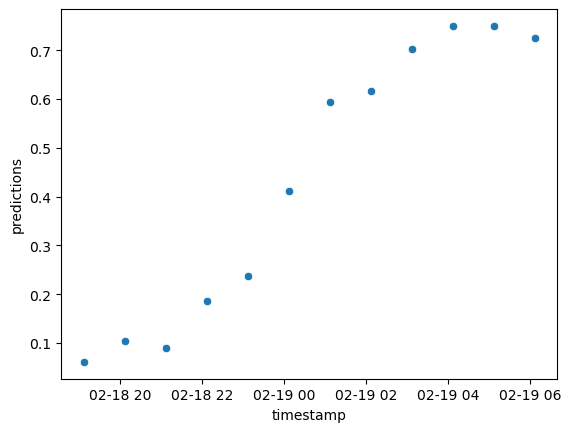

In [21]:
sns.scatterplot(data = predictions['5159.04'].iloc[0:12], x = 'timestamp', y = 'predictions')